# Filtre passe-haut : le miroir du passe-bas

**Projet EGALIZE — étude n° 2**

Un **passe-haut** fait l'inverse du passe-bas : il **garde les aigus** et **atténue les graves**. Image : le petit haut-parleur d'un téléphone, qui ne reproduit pas les basses.

L'idée clé de ce notebook tient en une ligne :

$$\text{passe-haut}(x) = x - \text{passe-bas}(x)$$

Si le passe-bas garde « ce qui varie lentement », ce qu'il **ne garde pas** est exactement « ce qui varie vite ». On réutilise donc les deux passe-bas du notebook 01.

1. Rappel des passe-bas et du signal de test.
2. Passe-haut n° 1 : **signal − lissage exponentiel**.
3. Passe-haut n° 2 : **signal − moyenne mobile**.
4. Comparaison avant / après.
5. Gain sur la bande des aigus.

Coupure visée : **fc = 4 000 Hz**, la frontière médiums / aigus d'EGALIZE.

**Mode d'emploi :** exécutez les cellules dans l'ordre (**Exécuter tout**). Chaque cellule de code est précédée d'une note qui dit ce qu'elle fait.

## 0. Préparation

> **Ce que fait la cellule suivante :** elle importe les bibliothèques, fixe les paramètres (`FS`, `DUREE`, la coupure `FC`) et **fabrique le signal de test** `x` : les trois mêmes notes que dans le notebook 01 (100 Hz, 1 kHz, 5 kHz).

Elle définit aussi des outils de **mesure** (spectre, amplitude d'une note, conversion en dB, écoute sans normalisation) et des outils d'**affichage**. Ces derniers servent seulement à dessiner les graphiques : inutile de les lire pour comprendre les filtres.

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Audio, display

FS = 44_100      # fréquence d'échantillonnage (Hz)
DUREE = 2.0      # durée du signal de test (s)
FC = 4000.0      # coupure du passe-haut (Hz) : frontière médiums / aigus
COUPURES = [FC]
ZONE = (FC, FS / 2)

NUIT, BLEU, OR, VIOLET, GRIS, ROUGE = "#0b1a33", "#1f5bff", "#c58c12", "#7c5cff", "#9aa6bb", "#e5484d"
plt.rcParams.update({
    "figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 12, "axes.titleweight": "bold", "legend.fontsize": 9,
})

# --- Signal de test : les trois mêmes notes que dans le notebook 01 ----------
t = np.arange(int(DUREE * FS)) / FS
COMPOSANTES = {"Grave 100 Hz": (100, 0.30), "Médium 1 kHz": (1000, 0.20), "Aigu 5 kHz": (5000, 0.12)}
sinusoides = {nom: A * np.sin(2 * np.pi * f * t) for nom, (f, A) in COMPOSANTES.items()}
x = sum(sinusoides.values())


# --- Mesures ------------------------------------------------------------------
def en_db(rapport):
    # Rapport d'amplitudes -> décibels : 0,5 -> −6 dB ; 2 -> +6 dB ; 1 -> 0 dB
    return 20 * np.log10(np.abs(rapport))


def db_vers_facteur(gain_db):
    # Décibels -> facteur d'amplitude : +6 dB -> ×2 ; −6 dB -> ×0,5
    return 10 ** (gain_db / 20)


def spectre_db(signal):
    # Spectre d'amplitude (dB) par FFT. Le facteur 2/N redonne l'amplitude de chaque sinusoïde.
    N = len(signal)
    amplitudes = 2 * np.abs(np.fft.rfft(signal)) / N
    return np.fft.rfftfreq(N, 1 / FS), 20 * np.log10(np.maximum(amplitudes, 1e-6))


def amplitude_a(signal, f):
    # Amplitude de la note de fréquence f : case numéro k = f × N / FS de la FFT.
    N = len(signal)
    return 2 * np.abs(np.fft.rfft(signal)[int(round(f * N / FS))]) / N


def ecouter(signal, titre):
    # Lecteur audio sans normalisation (niveau réel) ; refuse un signal qui écrêterait (> 1).
    crete = np.max(np.abs(signal))
    print(f"{titre} — crête : {crete:.2f} ({en_db(crete):.1f} dBFS)")
    if crete > 1:
        print("  Le signal dépasse 1 (0 dBFS) : il écrêterait. Lecture refusée.")
        return
    display(Audio(signal, rate=FS, normalize=False))


# --- Outils d'affichage (inutile de les lire pour comprendre les filtres) -----
def axe_frequences(ax):
    ticks = [20, 50, 100, 200, 500, 1000, 2000, 5000, 10000, 20000]
    ax.set_xscale("log")
    ax.set_xlim(20, FS / 2)
    ax.set_xticks(ticks, ["20", "50", "100", "200", "500", "1k", "2k", "5k", "10k", "20k"])
    ax.set_xlabel("Fréquence (Hz, échelle logarithmique)")


def coupures(ax):
    for fc in COUPURES:
        ax.axvline(fc, color=OR, ls="--", lw=1.2)


def fenetre(duree_ms):
    masque = (t >= 0.5) & (t < 0.5 + duree_ms / 1000)
    return masque, (t[masque] - 0.5) * 1000


def tracer_signal():
    masque, t_ms = fenetre(20)
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 7))
    for (nom, s), couleur in zip(sinusoides.items(), [BLEU, OR, VIOLET]):
        ax1.plot(t_ms, s[masque], color=couleur, lw=1, alpha=0.55, label=nom)
    ax1.plot(t_ms, x[masque], color=NUIT, lw=1.8, label="Somme = signal de test")
    ax1.set(title="Signal de test : trois notes (zoom sur 20 ms)", xlabel="Temps (ms)", ylabel="Amplitude")
    ax1.legend(loc="upper right", ncol=4)
    f, db = spectre_db(x)
    ax2.plot(f[1:], db[1:], color=NUIT, lw=1.4, label="Spectre")
    ax2.axvspan(*ZONE, color=VIOLET if ZONE[0] > 1000 else OR, alpha=0.1, label=f"Zone gardée par le filtre")
    coupures(ax2)
    axe_frequences(ax2)
    ax2.set(title="Spectre du signal de test", ylabel="Amplitude (dB)", ylim=(-80, 0))
    ax2.legend(loc="upper right")
    fig.tight_layout()
    plt.show()


def tracer_avant_apres(cible, sorties, duree_ms, titre):
    masque, t_ms = fenetre(duree_ms)
    fig, ax = plt.subplots(figsize=(11, 4.5))
    ax.plot(t_ms, x[masque], color=GRIS, lw=1, label="Avant : signal de test")
    ax.plot(t_ms, sinusoides[cible][masque], color=NUIT, lw=1.2, ls=":", label=f"Cible : {cible.lower()} seule")
    for signal, couleur, etiquette in sorties:
        ax.plot(t_ms, signal[masque], color=couleur, lw=2, label=etiquette)
    ax.set(title=titre, xlabel="Temps (ms)", ylabel="Amplitude")
    ax.legend(loc="upper right", ncol=2)
    fig.tight_layout()
    plt.show()


def tracer_spectres(sorties):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.6), gridspec_kw={"width_ratios": [1.6, 1]})
    f, db = spectre_db(x)
    ax1.plot(f[1:], db[1:], color=GRIS, lw=1.2, label="Avant")
    for signal, couleur, etiquette in sorties:
        ax1.plot(f[1:], spectre_db(signal)[1][1:], color=couleur, lw=1.2, label=etiquette)
    coupures(ax1)
    axe_frequences(ax1)
    ax1.set(title="Spectres avant / après filtrage", ylabel="Amplitude (dB)", ylim=(-110, 0))
    ax1.legend(loc="lower left")
    noms = list(COMPOSANTES)
    positions = np.arange(len(noms))
    series = [(x, GRIS, "Avant"), *sorties]
    largeur = 0.8 / len(series)
    for i, (signal, couleur, etiquette) in enumerate(series):
        valeurs = np.array([en_db(amplitude_a(signal, COMPOSANTES[n][0])) for n in noms])
        ax2.bar(positions + (i - (len(series) - 1) / 2) * largeur, valeurs + 70, bottom=-70, width=largeur, color=couleur, label=etiquette)
    ax2.set_xticks(positions, noms)
    ax2.set(title="Amplitude de chaque note", ylabel="Amplitude (dB)", ylim=(-70, 0))
    ax2.legend(loc="upper left")
    fig.tight_layout()
    plt.show()


def tableau_mesures(methodes):
    # methodes : liste de (nom court, signal filtré, fonction gain théorique |H(f)|)
    lignes = []
    for nom, (freq, A) in COMPOSANTES.items():
        ligne = {"Note": nom}
        for court, signal, theorie in methodes:
            ligne[f"{court} : mesuré (dB)"] = en_db(amplitude_a(signal, freq) / A)
            ligne[f"{court} : théorie (dB)"] = en_db(theorie(freq))
        lignes.append(ligne)
    return pd.DataFrame(lignes).set_index("Note").style.format("{:+.1f}")


def tracer_reponses(methodes, ideal):
    # methodes : liste de (signal filtré, fonction gain théorique, couleur, étiquette)
    f_axe = np.logspace(np.log10(20), np.log10(FS / 2), 2000)
    fig, ax = plt.subplots(figsize=(11, 4.8))
    ax.plot(*ideal, color=GRIS, lw=2.5, alpha=0.6, label="Filtre idéal (impossible)")
    for signal, theorie, couleur, etiquette in methodes:
        ax.plot(f_axe, en_db(theorie(f_axe) + 1e-12), color=couleur, lw=1.8, label=etiquette)
        for nom, (freq, A) in COMPOSANTES.items():
            ax.plot(freq, en_db(amplitude_a(signal, freq) / A), "o", color=couleur, ms=7, mec="white")
    ax.axhline(-3, color=NUIT, ls=":", lw=1, label="−3 dB")
    coupures(ax)
    axe_frequences(ax)
    ax.set(title="Réponse en fréquence (courbes : théorie, points : mesures)", ylabel="Gain (dB)", ylim=(-80, 5))
    ax.legend(loc="lower right")
    fig.tight_layout()
    plt.show()


def tracer_gain(x_eq, morceaux, titre_gain, duree_ms=20):
    masque, t_ms = fenetre(duree_ms)
    fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(11, 11))
    ax1.plot(t_ms, x[masque], color=GRIS, lw=1.2, label="Signal de test x")
    for signal, couleur, etiquette in morceaux:
        ax1.plot(t_ms, signal[masque], color=couleur, lw=1.6, label=etiquette)
    ax1.set(title="Séparer la bande du reste", xlabel="Temps (ms)", ylabel="Amplitude")
    ax1.legend(loc="upper right", ncol=3)
    ax2.plot(t_ms, x[masque], color=GRIS, lw=1.6, label="Avant")
    ax2.plot(t_ms, x_eq[masque], color=BLEU, lw=1.8, label=f"Après : {titre_gain}")
    ax2.axhline(1, color=ROUGE, ls="--", lw=1)
    ax2.axhline(-1, color=ROUGE, ls="--", lw=1, label="Limite d'écrêtage (±1)")
    ax2.set(title="Le signal avant / après le gain", xlabel="Temps (ms)", ylabel="Amplitude")
    ax2.legend(loc="upper right", ncol=3)
    f, db_avant = spectre_db(x)
    ax3.plot(f[1:], db_avant[1:], color=GRIS, lw=1.4, label="Avant")
    ax3.plot(f[1:], spectre_db(x_eq)[1][1:], color=BLEU, lw=1.4, label="Après")
    for nom, (freq, A) in COMPOSANTES.items():
        ax3.annotate(f"{en_db(amplitude_a(x_eq, freq) / A):+.1f} dB", (freq, en_db(amplitude_a(x_eq, freq))),
                     xytext=(0, 8), textcoords="offset points", ha="center", color=BLEU, fontweight="bold")
    coupures(ax3)
    axe_frequences(ax3)
    ax3.set(title="Spectres avant / après : variation de chaque note", ylabel="Amplitude (dB)", ylim=(-110, 5))
    ax3.legend(loc="lower left")
    fig.tight_layout()
    plt.show()


def resume_gains(x_eq, voulus):
    lignes = [{"Note": nom, "Gain voulu (dB)": voulus[nom], "Gain obtenu (dB)": en_db(amplitude_a(x_eq, f) / A)}
              for nom, (f, A) in COMPOSANTES.items()]
    display(pd.DataFrame(lignes).set_index("Note").style.format("{:+.1f}"))

> **Ce que fait la cellule suivante :** elle redéfinit les deux passe-bas du notebook 01 (`lissage_exponentiel` et `moyenne_mobile`) et leurs formules de gain. Le passe-haut va être construit **à partir d'eux**.

In [2]:
# Rappel du notebook 01 : les deux passe-bas « à la main »

def lissage_exponentiel(x, alpha):
    # y[n] = y[n-1] + alpha * (x[n] - y[n-1])
    y = np.zeros_like(x)
    precedent = 0.0
    for n in range(len(x)):
        precedent = precedent + alpha * (x[n] - precedent)
        y[n] = precedent
    return y


def alpha_pour(fc):
    # coefficient du lissage exponentiel pour une coupure fc
    return 1 - np.exp(-2 * np.pi * fc / FS)


def gain_lissage(f, alpha):
    # gain complexe H(f) du lissage exponentiel (le module donne l'atténuation)
    z = np.exp(-2j * np.pi * np.asarray(f, dtype=float) / FS)
    return alpha / (1 - (1 - alpha) * z)


def moyenne_mobile(x, M):
    # moyenne des M derniers échantillons
    y = np.zeros_like(x)
    somme = 0.0
    for n in range(len(x)):
        somme += x[n]
        if n >= M:
            somme -= x[n - M]
        y[n] = somme / M
    return y


def gain_moyenne_mobile_reel(f, M):
    # sin(pi f M / fs) / (M sin(pi f / fs)) : le gain de la moyenne mobile, retard mis à part
    w = np.pi * np.asarray(f, dtype=float) / FS
    with np.errstate(invalid="ignore", divide="ignore"):
        h = np.sin(M * w) / (M * np.sin(w))
    return np.where(w == 0, 1.0, h)

## 1. Le signal de test

Les trois mêmes notes que dans le notebook 01. Le passe-haut doit garder **l'aiguë (5 kHz)** et faire disparaître la grave et la médium.

> **Ce que fait la cellule suivante :** elle trace le signal dans le temps (zoom sur 20 ms) et son spectre, puis affiche un lecteur pour l'écouter.

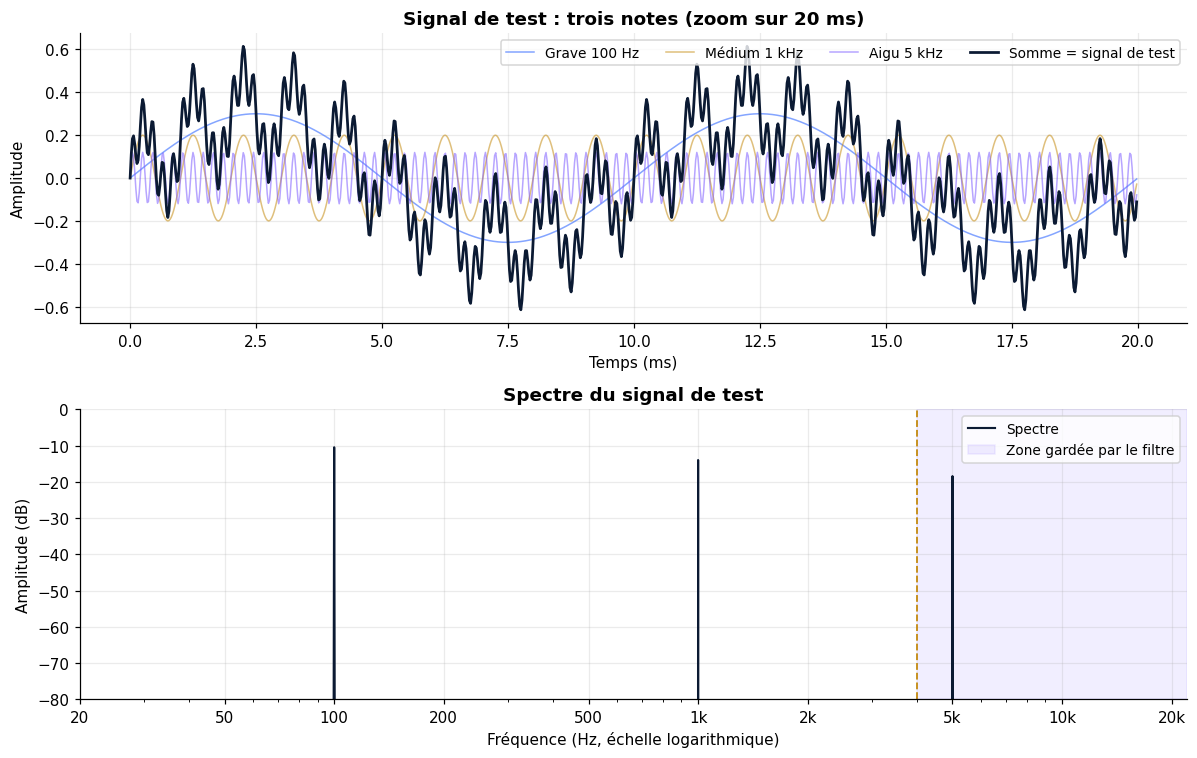

Signal de test — crête : 0.61 (-4.2 dBFS)


In [3]:
tracer_signal()
ecouter(x, "Signal de test")

> **Comment lire le résultat :** en bas, la zone colorée va de 4 kHz à 22 kHz : c'est ce que le passe-haut doit garder. Seul le pic de 5 kHz s'y trouve.

## 2. Passe-haut n° 1 : signal − lissage exponentiel

$$y[n] = x[n] - \text{lissage}(x)[n]$$

Son gain se déduit directement de celui du passe-bas :

$$H_{\text{haut}}(f) = 1 - H_{\text{bas}}(f)$$

**Bonus** : en développant le calcul, on retrouve une récurrence connue, celle du **circuit CR** (le passe-haut électronique d'ordre 1) :

$$y[n] = (1-\alpha)\,\big(y[n-1] + x[n] - x[n-1]\big)$$

On vérifie ci-dessous que les deux écritures donnent exactement le même signal.

**Réglage.** La formule $\alpha = 1 - e^{-2\pi f_c/f_s}$ du notebook 01 n'est exacte que pour une coupure **très petite devant fs**. À 4 kHz, on n'est qu'à 1/11 de fs, et la soustraction ne donne pas −3 dB pile. On cherche donc le bon réglage **numériquement**, comme on l'avait fait pour la longueur M de la moyenne mobile.

> **Ce que fait la cellule suivante :** elle définit trois fonctions :

- `passe_haut_soustraction` : le passe-haut, simplement `x − lissage(x)` ;
- `passe_haut_recurrence` : la même chose écrite comme le circuit CR, pour vérifier l'équivalence ;
- `gain_ph_lissage` : son gain théorique, `1 − gain du passe-bas`.

Elle montre ensuite que la formule de α du notebook 01 ne donne pas −3 dB à 4 kHz. Elle **essaie alors 9 801 valeurs de α** et garde celle qui donne −3 dB. Enfin, elle filtre le signal et vérifie que les deux écritures donnent le même résultat.

In [4]:
def passe_haut_soustraction(x, alpha):
    # Passe-haut = signal − passe-bas : on retire ce qui varie lentement, il reste ce qui varie vite.
    return x - lissage_exponentiel(x, alpha)


def passe_haut_recurrence(x, alpha):
    # Même filtre, écrit comme le circuit CR : y[n] = (1 - alpha) * (y[n-1] + x[n] - x[n-1]).
    # x[n] - x[n-1] est la variation d'un échantillon à l'autre : grande pour les aigus, petite pour les graves.
    y = np.zeros_like(x)
    y_prec, x_prec = 0.0, 0.0                 # y[n-1] et x[n-1]
    for n in range(len(x)):
        y_prec = (1 - alpha) * (y_prec + x[n] - x_prec)
        x_prec = x[n]
        y[n] = y_prec
    return y


def gain_ph_lissage(f, alpha):
    # Gain du passe-haut = 1 − gain du passe-bas (nombres complexes : la phase compte).
    return 1 - gain_lissage(f, alpha)


# 1. Avec la formule du notebook 01, le gain à FC n'est pas −3 dB
alpha_formule = alpha_pour(FC)
print(f"Avec la formule du notebook 01 : gain à {FC:.0f} Hz = {en_db(gain_ph_lissage(FC, alpha_formule)):.1f} dB (on voulait −3 dB)")

# 2. Recherche numérique : parmi 9 801 valeurs de alpha, laquelle donne −3 dB à FC ?
candidats = np.linspace(0.01, 0.99, 9801)
alpha = float(candidats[np.argmin(np.abs(en_db(gain_ph_lissage(FC, candidats)) + 3))])
print(f"alpha retenu = {alpha:.4f} → gain à {FC:.0f} Hz = {en_db(gain_ph_lissage(FC, alpha)):.2f} dB")

# 3. Filtrage et vérification de l'équivalence soustraction / circuit CR
y_exp = passe_haut_soustraction(x, alpha)
print("Soustraction et récurrence CR identiques :", np.allclose(y_exp, passe_haut_recurrence(x, alpha)))

Avec la formule du notebook 01 : gain à 4000 Hz = -5.6 dB (on voulait −3 dB)
alpha retenu = 0.2981 → gain à 4000 Hz = -3.00 dB


Soustraction et récurrence CR identiques : True


> **Comment lire le résultat :** avec le bon α (≈ 0,30), le gain vaut exactement −3 dB à 4 kHz. `True` confirme que « signal − passe-bas » et le circuit CR sont **le même filtre**, écrit de deux façons.

## 3. Passe-haut n° 2 : signal − moyenne mobile

Même idée avec la moyenne mobile, mais avec une précaution. La moyenne des M derniers échantillons représente le signal **tel qu'il était au milieu de la fenêtre**, soit $D = (M-1)/2$ échantillons plus tôt. Pour soustraire des choses comparables, on retarde aussi le signal de D échantillons :

$$y[n] = x[n - D] - \text{moyenne}_M(x)[n]$$

On prend M **impair** pour que D soit un nombre entier. Le gain vaut alors :

$$|H(f)| = \left| 1 - \frac{\sin(\pi f M / f_s)}{M\,\sin(\pi f / f_s)} \right|$$

Comme pour le passe-bas, on cherche le M qui donne −3 dB à 4 kHz. Ici la fenêtre est **très courte** : quelques échantillons seulement. M ne pouvant prendre que des valeurs entières, on n'atteindra pas −3 dB exactement.

> **Ce que fait la cellule suivante :** elle définit `passe_haut_moyenne` (signal retardé − moyenne mobile) et sa formule de gain. Elle **essaie toutes les longueurs impaires** de 3 à 199, garde celle qui donne le gain le plus proche de −3 dB à 4 kHz, puis filtre le signal.

In [5]:
def passe_haut_moyenne(x, M):
    D = (M - 1) // 2                                            # retard de la moyenne mobile (centre de la fenêtre)
    retarde = np.concatenate([np.zeros(D), x[: len(x) - D]])   # x[n - D] : le signal décalé de D échantillons
    return retarde - moyenne_mobile(x, M)                      # signal (aligné) − ce que garde le passe-bas


def gain_ph_moyenne(f, M):
    # Gain = 1 − gain de la moyenne mobile (les retards étant alignés, on peut soustraire directement)
    return 1 - gain_moyenne_mobile_reel(f, M)


# Recherche de M parmi les longueurs impaires (pour que le retard D soit entier)
impairs = np.arange(3, 201, 2)
M = int(impairs[np.argmin([abs(en_db(gain_ph_moyenne(FC, m)) + 3) for m in impairs])])
print(f"M = {M} échantillons (retard D = {(M - 1) // 2}) → gain à {FC:.0f} Hz = {en_db(gain_ph_moyenne(FC, M)):.1f} dB")

y_mm = passe_haut_moyenne(x, M)

M = 9 échantillons (retard D = 4) → gain à 4000 Hz = -2.1 dB


> **Comment lire le résultat :** une fenêtre de seulement **9 échantillons** suffit. M ne peut pas valoir 8,5 : le meilleur choix donne −2,1 dB au lieu de −3 dB à 4 kHz.

## 4. Comparer avant / après

### 4.1 Dans le temps (zoom sur 3 ms)

La sortie doit ressembler à l'aiguë seule : une oscillation rapide, sans la grande ondulation de la grave.

> **Ce que fait la cellule suivante :** elle superpose, sur 3 ms : le signal d'origine (gris), l'**aiguë seule** (pointillés, la cible idéale) et les sorties des deux passe-haut.

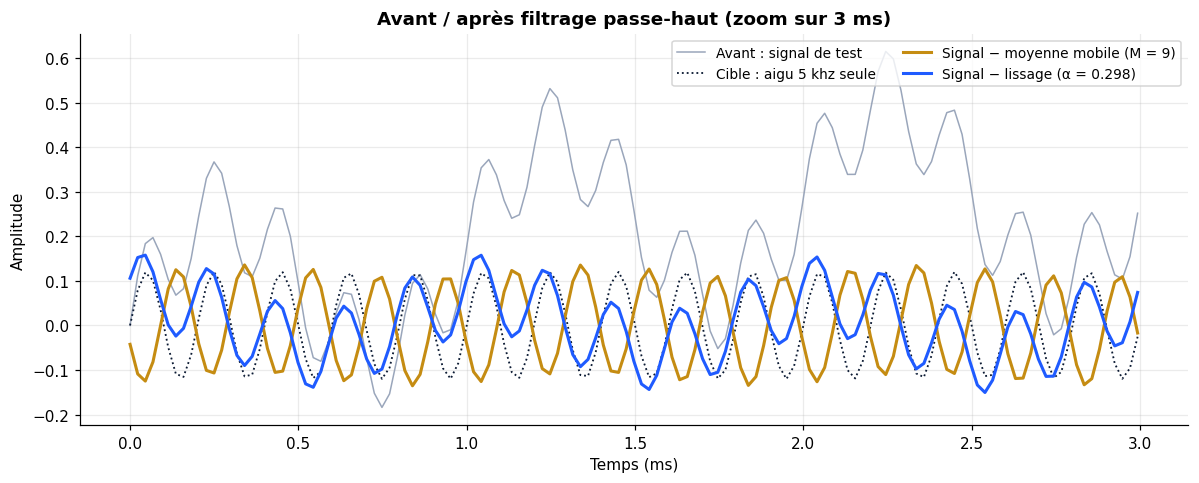

In [6]:
tracer_avant_apres(
    "Aigu 5 kHz",
    [(y_mm, OR, f"Signal − moyenne mobile (M = {M})"), (y_exp, BLEU, f"Signal − lissage (α = {alpha:.3f})")],
    duree_ms=3,
    titre="Avant / après filtrage passe-haut (zoom sur 3 ms)",
)

> **Comment lire le résultat :** les sorties oscillent vite autour de zéro, comme l'aiguë seule : la grande ondulation de la grave a disparu. La sortie « lissage » garde encore un peu de médium, ce qui se voit à son enveloppe qui ondule.

### 4.2 Dans les fréquences

> **Ce que fait la cellule suivante :** elle trace, à gauche, les spectres avant et après chaque passe-haut. À droite, elle résume l'amplitude de chaque note sous forme de barres.

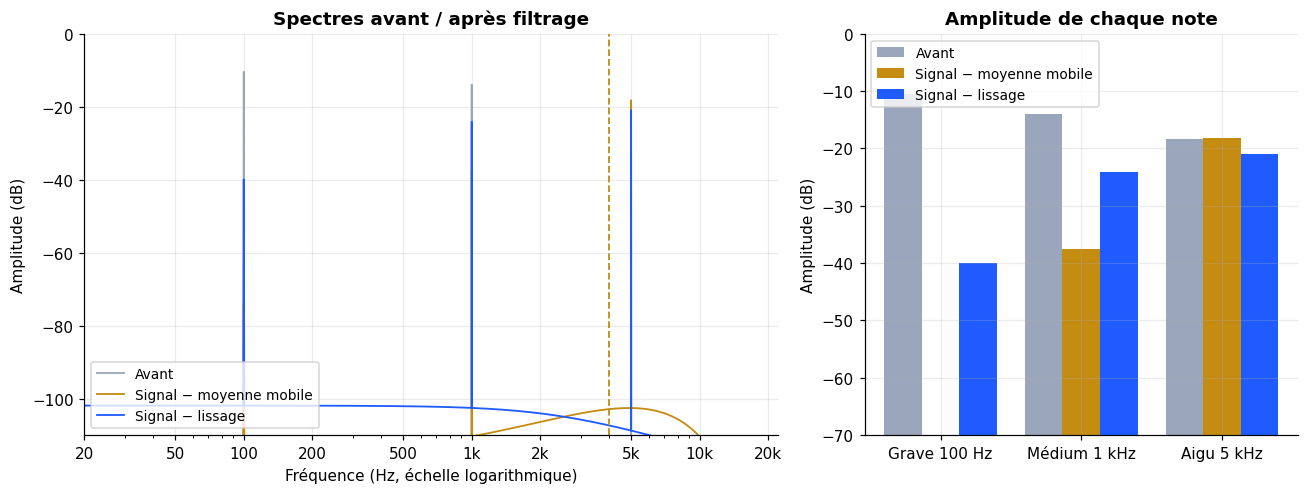

In [7]:
tracer_spectres([(y_mm, OR, "Signal − moyenne mobile"), (y_exp, BLEU, "Signal − lissage")])

> **Comment lire le résultat :** c'est l'inverse du passe-bas : le pic de 5 kHz reste presque au même niveau, ceux de 100 Hz et 1 kHz chutent fortement.

### 4.3 Mesures contre théorie

> **Ce que fait la cellule suivante :** elle compare, pour chaque note, le gain **mesuré** dans le spectre et le gain **prévu** par la formule de chaque passe-haut.

In [8]:
tableau_mesures([
    ("Moy. mobile", y_mm, lambda f: gain_ph_moyenne(f, M)),
    ("Lissage", y_exp, lambda f: gain_ph_lissage(f, alpha)),
])

,Moy. mobile : mesuré (dB),Moy. mobile : théorie (dB),Lissage : mesuré (dB),Lissage : théorie (dB)
Note,,,,
Grave 100 Hz,-63.4,-63.4,-29.5,-29.5
Médium 1 kHz,-23.6,-23.6,-10.1,-10.1
Aigu 5 kHz,+0.2,+0.2,-2.5,-2.5


> **Comment lire le résultat :** mesure et théorie sont identiques pour chaque note. Plus la note est grave, plus elle est atténuée.

> **Ce que fait la cellule suivante :** elle trace le gain des deux passe-haut **pour toutes les fréquences** (courbes), avec les mesures (points) et le filtre idéal (gris).

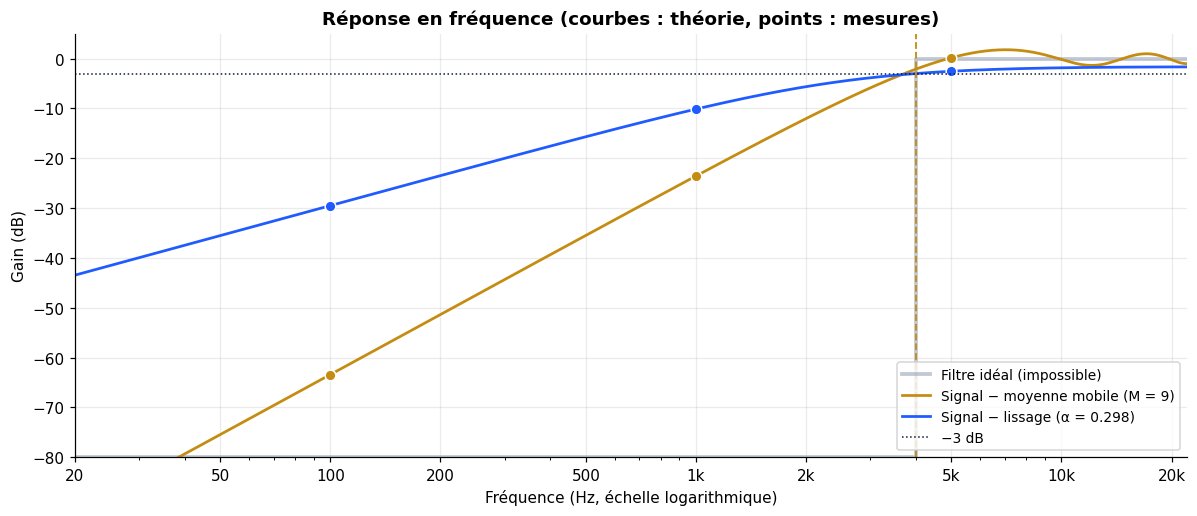

In [9]:
tracer_reponses(
    [(y_mm, lambda f: gain_ph_moyenne(f, M), OR, f"Signal − moyenne mobile (M = {M})"),
     (y_exp, lambda f: gain_ph_lissage(f, alpha), BLEU, f"Signal − lissage (α = {alpha:.3f})")],
    ideal=([20, FC, FC, FS / 2], [-80, -80, 0, 0]),
)

**À retenir**

- La courbe du passe-haut est le **miroir** de celle du passe-bas : elle monte vers les aigus au lieu de descendre.
- **Les deux méthodes laissent passer l'aiguë** (5 kHz : +0,2 dB avec la moyenne mobile, −2,5 dB avec le lissage, car 5 kHz est encore tout près de la coupure). La grave (100 Hz) est très atténuée (−63 et −30 dB), la médium (1 kHz) nettement (−24 et −10 dB).
- **La version « moyenne mobile »** descend plus vite vers les graves, mais ondule légèrement au-dessus de 0 dB dans les aigus.
- **La version « lissage »** est régulière : −6 dB par octave en descendant, comme tout filtre d'ordre 1.
- Les points de mesure tombent sur les courbes théoriques.

### 4.4 À l'écoute

> **Ce que fait la cellule suivante :** elle affiche trois lecteurs : l'original, puis la sortie de chaque passe-haut. Après filtrage, il ne reste qu'un **sifflement aigu** : la grave et la médium ont (presque) disparu.

In [10]:
ecouter(x, "Avant")
ecouter(y_mm, "Signal − moyenne mobile")
ecouter(y_exp, "Signal − lissage exponentiel")

Avant — crête : 0.61 (-4.2 dBFS)


Signal − moyenne mobile — crête : 0.14 (-17.3 dBFS)


Signal − lissage exponentiel — crête : 0.16 (-15.9 dBFS)


## 5. Appliquer un gain à la bande des aigus

Même recette que pour les graves dans le notebook 01 :

1. `aigus = passe_haut(x)`
2. `reste = x − aigus` : c'est tout ce qui n'est pas aigu (le passe-bas).
3. `x_eq = reste + facteur × aigus`

À 0 dB, on doit retrouver exactement x.

> **Ce que fait la cellule suivante :** elle applique ces trois étapes avec un gain de **+6 dB**, vérifie qu'à 0 dB on retrouve x et que la crête reste sous 1. Elle trace ensuite la séparation, le signal avant / après et les spectres. Pour finir, elle affiche le tableau gain voulu / gain obtenu et les lecteurs.

Changez `G_DB` pour essayer d'autres gains.

Gain des aigus : +6.0 dB (amplitude × 1.995)
Vérification à 0 dB : on retrouve exactement x ? True
Crête avant : 0.615 — après : 0.727


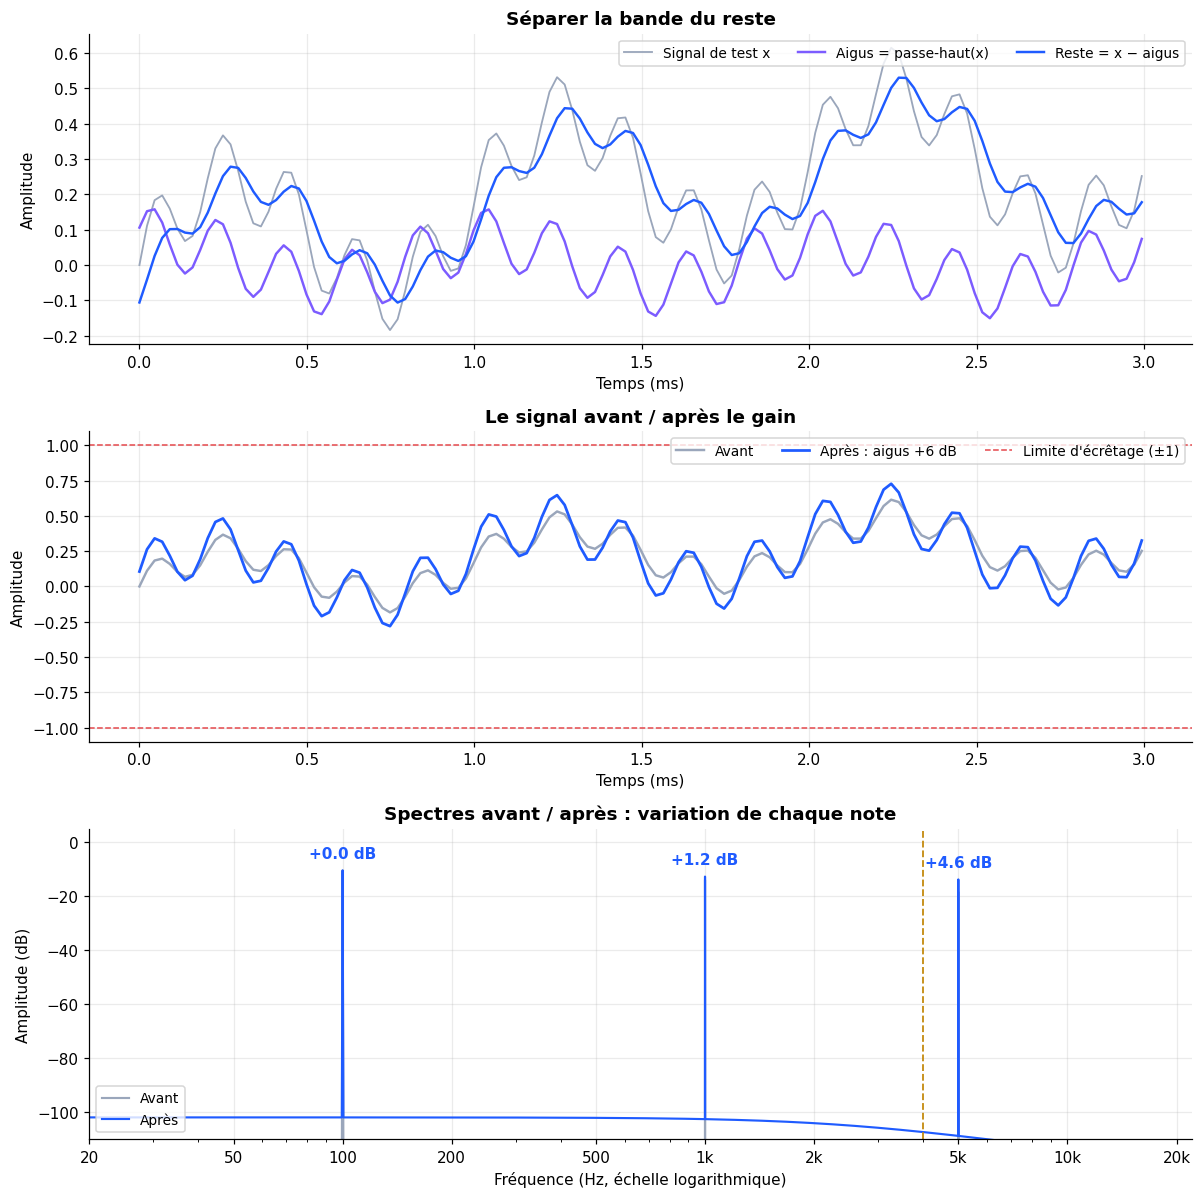

,Gain voulu (dB),Gain obtenu (dB)
Note,,
Grave 100 Hz,+0.0,+0.0
Médium 1 kHz,+0.0,+1.2
Aigu 5 kHz,+6.0,+4.6


Avant — crête : 0.61 (-4.2 dBFS)


Après : aigus +6 dB — crête : 0.73 (-2.8 dBFS)


In [11]:
G_DB = 6.0                                   # gain sur les aigus (dB) : essayez −6, +3, +12…
facteur = db_vers_facteur(G_DB)

aigus = passe_haut_soustraction(x, alpha)    # 1. isoler les aigus
reste = x - aigus                            # 2. le reste
x_eq = reste + facteur * aigus               # 3. gain puis recombinaison

print(f"Gain des aigus : {G_DB:+.1f} dB (amplitude × {facteur:.3f})")
print("Vérification à 0 dB : on retrouve exactement x ?", np.allclose(reste + aigus, x))
print(f"Crête avant : {np.max(np.abs(x)):.3f} — après : {np.max(np.abs(x_eq)):.3f}")

tracer_gain(x_eq, [(aigus, VIOLET, "Aigus = passe-haut(x)"), (reste, BLEU, "Reste = x − aigus")],
            f"aigus {G_DB:+.0f} dB", duree_ms=3)
resume_gains(x_eq, {"Grave 100 Hz": 0.0, "Médium 1 kHz": 0.0, "Aigu 5 kHz": G_DB})
ecouter(x, "Avant")
ecouter(x_eq, f"Après : aigus {G_DB:+.0f} dB")

> **Comment lire le résultat :** l'aiguë gagne **+4,6 dB** au lieu de +6. À 5 kHz, elle est encore dans la zone de transition du filtre : seule une partie passe dans la bande « aigus » et reçoit le gain. La médium gagne +1,2 dB, car un filtre d'ordre 1 en laisse « fuir » une partie dans les aigus. La grave, très loin de la coupure, ne bouge pas.

## 6. Bilan

| | Signal − moyenne mobile | Signal − lissage exponentiel |
|---|---|---|
| Formule | $x[n-D] - \text{moyenne}_M(x)[n]$ | $x[n] - \text{lissage}(x)[n]$ |
| Équivalent | — | circuit CR : $y[n] = (1-\alpha)(y[n-1] + x[n] - x[n-1])$ |
| Gain | $1 - H_{\text{moyenne}}$ | $1 - H_{\text{lissage}}$ |
| Pente | rapide, petites ondulations | régulière, −6 dB par octave |

**À retenir** : un passe-haut s'obtient en **retirant au signal ce que garde un passe-bas**. C'est ainsi qu'EGALIZE calcule ses aigus : `aigus = x − passe_bas(x, coupure haute)`.

## 7. À vous de jouer

1. Mettez `FC = 500`. La médium (1 kHz) passe-t-elle maintenant ?
2. Dans la partie 3, retirez le retard (prenez `D = 0`) : que devient le passe-haut « moyenne mobile » ?
3. Mettez `G_DB = -12` : les aigus disparaissent-ils vraiment ?